# HIV/AIDS Burden in Africa & the USA — Exploratory Analysis

This notebook analyses the SQLite database produced by the pipeline
(`src/ingestion` → `src/transformation` → `src/loading`). It covers **15 African
countries** and the **United States** using five World Bank indicators:

| Indicator | World Bank ID |
|---|---|
| Prevalence of HIV, total (% of population ages 15-49) | `SH.DYN.AIDS.ZS` |
| Antiretroviral therapy coverage (% of people living with HIV) | `SH.HIV.ARTC.ZS` |
| Incidence of HIV, ages 15-49 (per 1,000 uninfected population ages 15-49) | `SH.HIV.INCD.ZS` |
| Adults (ages 15+) and children (0-14 years) living with HIV | `SH.HIV.TOTL` |
| Current health expenditure (% of GDP) | `SH.XPD.CHEX.GD.ZS` |

> **Data caveat:** the World Bank (sourcing UNAIDS estimates) publishes **no HIV
> prevalence, incidence, ART or PLHIV values for the United States**. US rows
> therefore carry health expenditure only, and the Africa-vs-USA comparison
> focuses on health-system spending alongside Africa's HIV outcomes.

In [1]:
%matplotlib inline
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio
import seaborn as sns

pio.renderers.default = "notebook_connected"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DB_PATH = ROOT / "data" / "hiv_aids.db"
assert DB_PATH.exists(), f"Run the pipeline first: {DB_PATH} not found"
conn = sqlite3.connect(DB_PATH)
print("Connected to", DB_PATH.relative_to(ROOT))

Connected to data/hiv_aids.db


## 1. Data loading & exploration

In [2]:
countries = pd.read_sql("SELECT * FROM countries", conn)
indicators = pd.read_sql("SELECT * FROM indicators", conn)
df = pd.read_sql(
    """SELECT m.*, c.country_name, c.iso3, c.region, c.subregion
       FROM hiv_metrics m JOIN countries c USING (country_code)""",
    conn,
)
print(f"countries={len(countries)}, indicators={len(indicators)}, hiv_metrics={len(df)}")
print("Years covered:", df.year.min(), "-", df.year.max())
indicators[["indicator_id", "indicator_name", "unit"]]

countries=16, indicators=5, hiv_metrics=175
Years covered: 2014 - 2024


,indicator_id,indicator_name,unit
0,SH.DYN.AIDS.ZS,"Prevalence of HIV, total (% of population ages...",percent
1,SH.HIV.ARTC.ZS,Antiretroviral therapy coverage (% of people l...,percent
2,SH.HIV.INCD.ZS,"Incidence of HIV, ages 15-49 (per 1,000 uninfe...",per_1000
3,SH.HIV.TOTL,Adults (ages 15+) and children (0-14 years) li...,people
4,SH.XPD.CHEX.GD.ZS,Current health expenditure (% of GDP),percent


In [3]:
countries.sort_values(["region", "subregion", "country_name"])

,country_code,iso3,country_name,region,subregion
1,CM,CMR,Cameroon,Africa,Central Africa
3,ET,ETH,Ethiopia,Africa,East Africa
5,KE,KEN,Kenya,Africa,East Africa
10,TZ,TZA,Tanzania,Africa,East Africa
11,UG,UGA,Uganda,Africa,East Africa
2,EG,EGY,"Egypt, Arab Rep.",Africa,North Africa
6,MA,MAR,Morocco,Africa,North Africa
7,MW,MWI,Malawi,Africa,Southern Africa
8,MZ,MOZ,Mozambique,Africa,Southern Africa
13,ZA,ZAF,South Africa,Africa,Southern Africa


In [4]:
VALUE_COLS = ["hiv_prevalence_pct", "art_coverage_pct", "hiv_incidence_per1000",
              "plhiv_count", "health_exp_pct_gdp"]
df[VALUE_COLS].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
hiv_prevalence_pct,150.0,5.69,5.36,0.10,1.52,3.70,9.80,18.60
art_coverage_pct,150.0,64.36,19.80,8.00,51.25,68.50,79.75,95.00
hiv_incidence_per1000,150.0,2.35,2.68,0.10,0.53,1.15,3.08,10.90
plhiv_count,150.0,1444280.00,1710758.63,20000.00,452500.00,1300000.00,1575000.00,7800000.00
health_exp_pct_gdp,160.0,5.69,3.31,2.43,3.72,4.56,6.63,18.52


In [5]:
# Non-null coverage per region — confirms the US has only health-expenditure data
df.groupby("region")[VALUE_COLS].apply(lambda g: g.notna().sum()).T

region,Africa,USA
hiv_prevalence_pct,150,0
art_coverage_pct,150,0
hiv_incidence_per1000,150,0
plhiv_count,150,0
health_exp_pct_gdp,150,10


In [6]:
LATEST = int(df.loc[df.hiv_prevalence_pct.notna(), "year"].max())
latest = df[df.year == LATEST].copy()
africa_latest = latest[latest.region == "Africa"].sort_values("hiv_prevalence_pct",
                                                              ascending=False)
print("Latest year with HIV data:", LATEST)
africa_latest[["country_name", "subregion", "hiv_prevalence_pct", "art_coverage_pct",
               "hiv_incidence_per1000", "plhiv_count", "treatment_gap"]].reset_index(drop=True)

Latest year with HIV data: 2024


,country_name,subregion,hiv_prevalence_pct,art_coverage_pct,hiv_incidence_per1000,plhiv_count,treatment_gap
0,South Africa,Southern Africa,17.2,81.0,5.20,7800000.0,1482000.0
1,Mozambique,Southern Africa,11.5,82.0,4.90,2500000.0,450000.0
2,Zimbabwe,Southern Africa,9.8,95.0,1.40,1300000.0,65000.0
3,Zambia,Southern Africa,9.4,94.0,2.80,1400000.0,84000.0
4,Malawi,Southern Africa,6.2,90.0,0.92,990000.0,99000.0
5,Uganda,East Africa,4.9,85.0,1.40,1500000.0,225000.0
6,Tanzania,East Africa,3.5,87.0,1.10,1800000.0,234000.0
7,Kenya,East Africa,3.0,87.0,0.53,1300000.0,169000.0
8,Cameroon,Central Africa,2.5,88.0,0.70,510000.0,61200.0
9,Cote d'Ivoire,West Africa,1.7,78.0,0.41,410000.0,90200.0


## 2. HIV prevalence by country

Southern Africa dominates: South Africa, Mozambique, Zimbabwe and Zambia all
have adult prevalence above 9%, while North African countries (Egypt, Morocco)
sit at 0.1%.

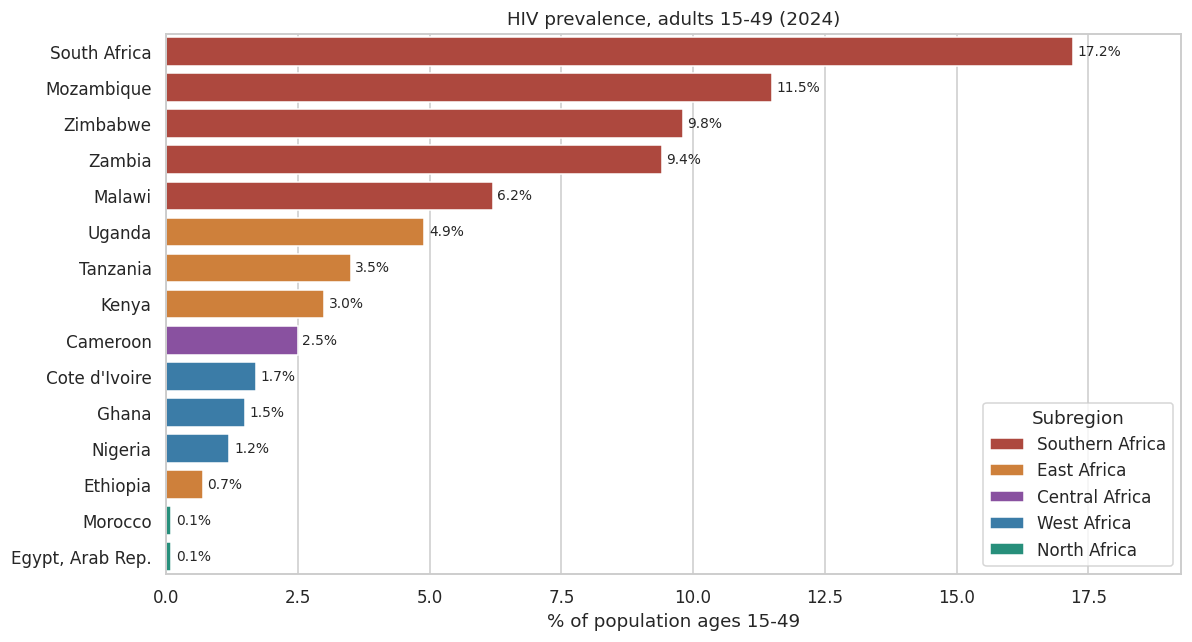

In [7]:
palette = {"Southern Africa": "#c0392b", "East Africa": "#e67e22",
           "Central Africa": "#8e44ad", "West Africa": "#2980b9",
           "North Africa": "#16a085"}
fig, ax = plt.subplots(figsize=(11, 6))
sns.barplot(data=africa_latest, y="country_name", x="hiv_prevalence_pct",
            hue="subregion", dodge=False, palette=palette, ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3, fontsize=9)
ax.set_xlim(0, africa_latest.hiv_prevalence_pct.max() * 1.12)
ax.set(title=f"HIV prevalence, adults 15-49 ({LATEST})", xlabel="% of population ages 15-49",
       ylabel="")
ax.legend(title="Subregion", loc="lower right")
plt.tight_layout()
plt.show()

## 3. ART coverage trends, 2015 → latest

Every country scaled up antiretroviral therapy. Zimbabwe (61% → 95%) and Zambia
(65% → 94%) now exceed the 95-95-95 treatment-equivalent level (90.25%), while
Ghana and Egypt remain below 50%.

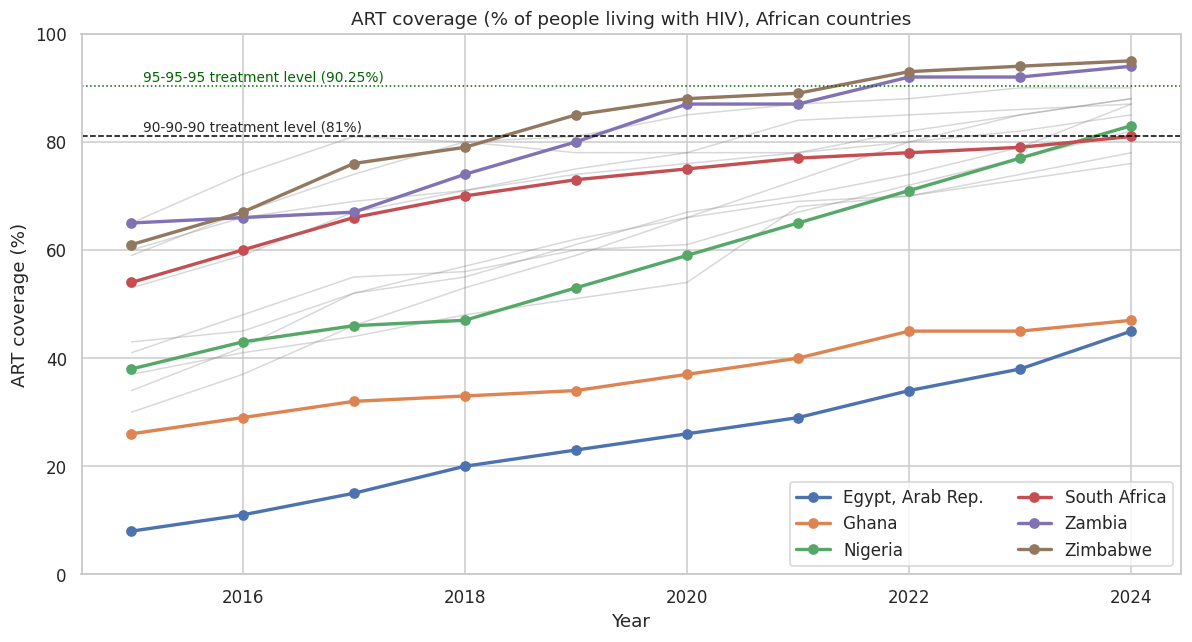

In [8]:
art = df[(df.region == "Africa") & df.art_coverage_pct.notna()]
highlight = ["Zimbabwe", "Zambia", "South Africa", "Nigeria", "Ghana", "Egypt, Arab Rep."]
fig, ax = plt.subplots(figsize=(11, 6))
for name, grp in art.groupby("country_name"):
    if name in highlight:
        ax.plot(grp.year, grp.art_coverage_pct, marker="o", linewidth=2.2, label=name)
    else:
        ax.plot(grp.year, grp.art_coverage_pct, color="grey", alpha=0.3, linewidth=1)
ax.axhline(81, ls="--", color="black", lw=1)
ax.text(2015.1, 82, "90-90-90 treatment level (81%)", fontsize=9)
ax.axhline(90.25, ls=":", color="darkgreen", lw=1)
ax.text(2015.1, 91.2, "95-95-95 treatment level (90.25%)", fontsize=9, color="darkgreen")
ax.set(title="ART coverage (% of people living with HIV), African countries",
       xlabel="Year", ylabel="ART coverage (%)", ylim=(0, 100))
ax.legend(loc="lower right", ncol=2)
plt.tight_layout()
plt.show()

## 4. Health expenditure vs HIV prevalence

Countries with the highest HIV burden also spend more on health relative to GDP
(South Africa, Mozambique). The relationship is largely *reverse causality*: a
heavy HIV epidemic drives health spending (much of it donor-financed via PEPFAR
and the Global Fund). The dashed line marks US health expenditure for context.

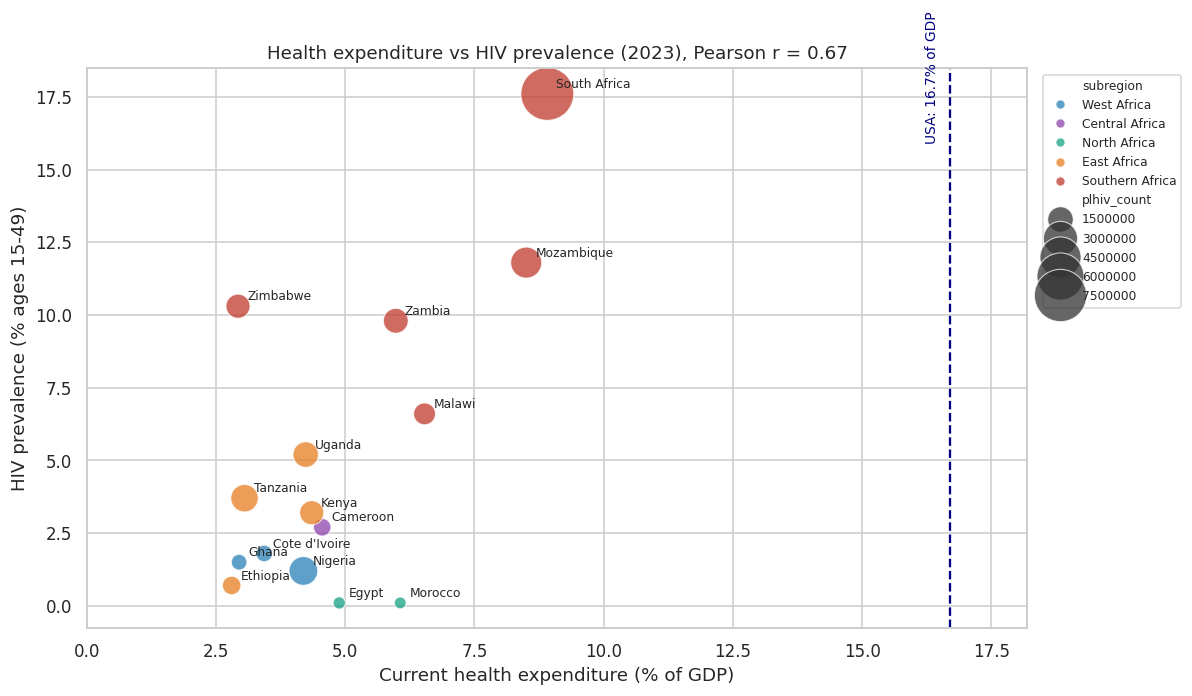

In [9]:
HE_YEAR = int(df.loc[df.health_exp_pct_gdp.notna() & df.hiv_prevalence_pct.notna(),
                     "year"].max())
sc = df[(df.year == HE_YEAR) & (df.region == "Africa")].dropna(
    subset=["health_exp_pct_gdp", "hiv_prevalence_pct"])
us_he = df[(df.country_code == "US") & (df.year == HE_YEAR)].health_exp_pct_gdp.iloc[0]
r = sc[["health_exp_pct_gdp", "hiv_prevalence_pct"]].corr().iloc[0, 1]

fig, ax = plt.subplots(figsize=(11, 6.5))
sns.scatterplot(data=sc, x="health_exp_pct_gdp", y="hiv_prevalence_pct", hue="subregion",
                size="plhiv_count", sizes=(60, 1200), palette=palette, alpha=0.75, ax=ax,
                legend="brief")
for _, row in sc.iterrows():
    ax.annotate(row.country_name.replace(", Arab Rep.", ""),
                (row.health_exp_pct_gdp, row.hiv_prevalence_pct),
                xytext=(6, 4), textcoords="offset points", fontsize=8)
ax.axvline(us_he, ls="--", color="navy")
ax.text(us_he - 0.2, 16, f"USA: {us_he:.1f}% of GDP", rotation=90, color="navy",
        ha="right", fontsize=9)
ax.set(title=f"Health expenditure vs HIV prevalence ({HE_YEAR}), Pearson r = {r:.2f}",
       xlabel="Current health expenditure (% of GDP)", ylabel="HIV prevalence (% ages 15-49)",
       xlim=(0, us_he + 1.5))
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

## 5. Indicator heatmap by country

Each column is min-max scaled across countries (0 = lowest, 1 = highest) so
indicators with different units are comparable; annotations show the raw values.
The US row appears only under health expenditure.

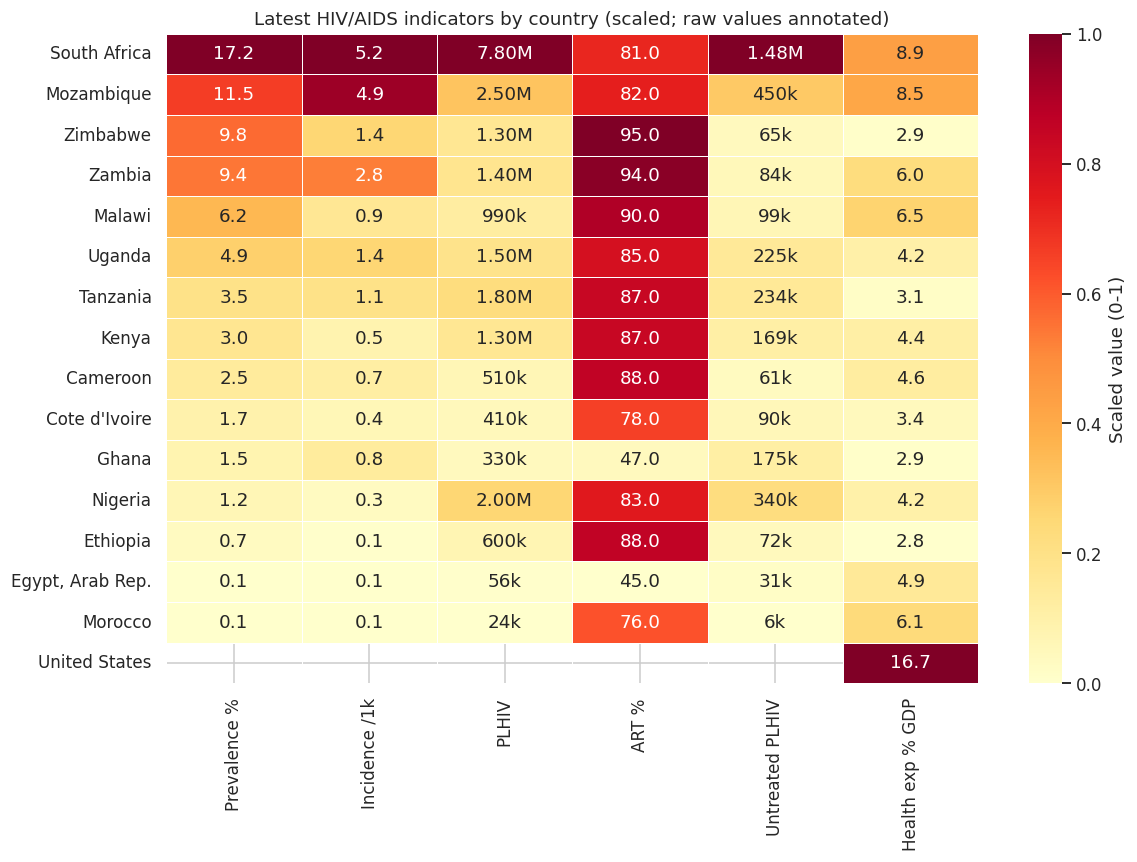

In [10]:
heat_cols = {"hiv_prevalence_pct": "Prevalence %", "hiv_incidence_per1000": "Incidence /1k",
             "plhiv_count": "PLHIV", "art_coverage_pct": "ART %",
             "treatment_gap": "Untreated PLHIV", "health_exp_pct_gdp": "Health exp % GDP"}
summary = pd.read_sql(
    """SELECT c.country_name, m.country_code, m.year, m.hiv_prevalence_pct,
              m.hiv_incidence_per1000, m.plhiv_count, m.art_coverage_pct,
              m.treatment_gap, m.health_exp_pct_gdp
       FROM hiv_metrics m JOIN countries c USING (country_code)""", conn)
# latest non-null value per country for each indicator
latest_vals = (summary.sort_values("year").groupby("country_name")[list(heat_cols)]
               .agg(lambda s: s.dropna().iloc[-1] if s.notna().any() else np.nan))
latest_vals = latest_vals.sort_values("hiv_prevalence_pct", ascending=False)
scaled = (latest_vals - latest_vals.min()) / (latest_vals.max() - latest_vals.min())

def fmt(v, col):
    if pd.isna(v):
        return ""
    if col in ("plhiv_count", "treatment_gap"):
        return f"{v / 1e6:.2f}M" if v >= 1e6 else f"{v / 1e3:.0f}k"
    return f"{v:.1f}"

annot = np.array([[fmt(latest_vals.iloc[i, j], c) for j, c in enumerate(heat_cols)]
                  for i in range(len(latest_vals))])
fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(scaled.rename(columns=heat_cols), annot=annot, fmt="", cmap="YlOrRd",
            linewidths=0.5, cbar_kws={"label": "Scaled value (0-1)"}, ax=ax)
ax.set(title="Latest HIV/AIDS indicators by country (scaled; raw values annotated)",
       xlabel="", ylabel="")
plt.tight_layout()
plt.show()

## 6. Africa vs USA comparison

Because the World Bank does not report HIV outcomes for the United States, the
directly comparable dimension is **health-system investment**. The US spends
roughly 16-18% of GDP on health — more than three times the African average of
about 5% — while the 15 African countries together carry over 22 million people
living with HIV.

*External context (not in this dataset):* the US CDC estimates roughly
1.2 million people were living with HIV in the United States in 2022.

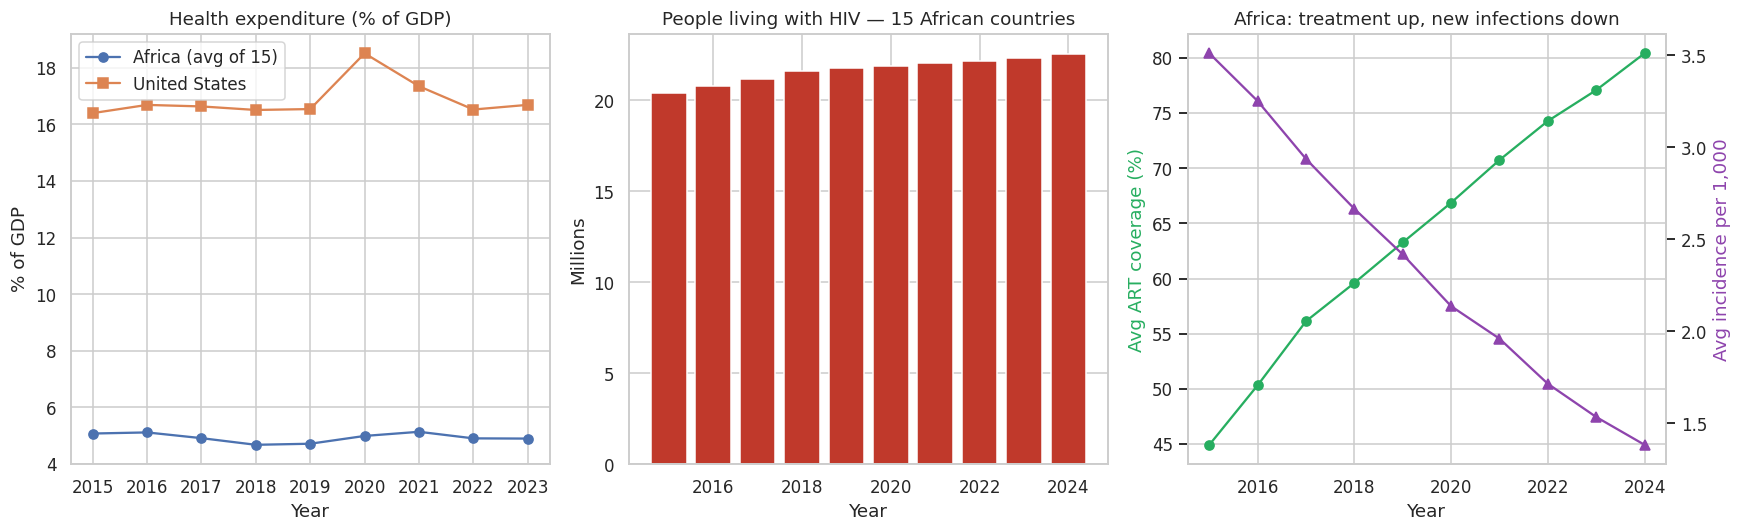

,region,year,health_exp,plhiv,art,incidence
15,USA,2020,18.52,0.0,NaN,NaN
16,USA,2021,17.35,0.0,NaN,NaN
17,USA,2022,16.53,0.0,NaN,NaN
18,USA,2023,16.69,0.0,NaN,NaN


In [11]:
region_year = (df[df.year.between(2015, LATEST)]
               .groupby(["region", "year"])
               .agg(health_exp=("health_exp_pct_gdp", "mean"),
                    plhiv=("plhiv_count", "sum"),
                    art=("art_coverage_pct", "mean"),
                    incidence=("hiv_incidence_per1000", "mean"))
               .reset_index())
africa_ry = region_year[region_year.region == "Africa"]
usa_ry = region_year[region_year.region == "USA"]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
axes[0].plot(africa_ry.year, africa_ry.health_exp, marker="o", label="Africa (avg of 15)")
axes[0].plot(usa_ry.year, usa_ry.health_exp, marker="s", label="United States")
axes[0].set(title="Health expenditure (% of GDP)", xlabel="Year", ylabel="% of GDP")
axes[0].legend()

axes[1].bar(africa_ry.year, africa_ry.plhiv / 1e6, color="#c0392b")
axes[1].set(title="People living with HIV — 15 African countries", xlabel="Year",
            ylabel="Millions")

ax2 = axes[2]
ax2.plot(africa_ry.year, africa_ry.art, marker="o", color="#27ae60", label="ART coverage %")
ax2.set_ylabel("Avg ART coverage (%)", color="#27ae60")
ax3 = ax2.twinx()
ax3.plot(africa_ry.year, africa_ry.incidence, marker="^", color="#8e44ad",
         label="Incidence per 1,000")
ax3.set_ylabel("Avg incidence per 1,000", color="#8e44ad")
ax2.set(title="Africa: treatment up, new infections down", xlabel="Year")
ax3.grid(False)
plt.tight_layout()
plt.show()

region_year.round(2).tail(4)

## 7. PLHIV burden map and treatment gap

The choropleth shows the absolute number of people living with HIV; bubble
sizes in the second chart show the estimated **untreated** population
(PLHIV × (1 − ART coverage)). South Africa alone accounts for roughly 41% of
the untreated population across the 15 countries.

In [12]:
plhiv_latest = africa_latest.dropna(subset=["plhiv_count"])
fig = px.choropleth(
    plhiv_latest, locations="iso3", color="plhiv_count", hover_name="country_name",
    hover_data={"hiv_prevalence_pct": True, "art_coverage_pct": True, "iso3": False},
    color_continuous_scale="Reds", scope="africa",
    labels={"plhiv_count": "PLHIV", "hiv_prevalence_pct": "Prevalence %",
            "art_coverage_pct": "ART %"},
    title=f"People living with HIV ({LATEST})",
)
fig.update_layout(height=550, margin=dict(l=0, r=0, t=50, b=0))
fig.show()

In [13]:
fig = px.scatter(
    plhiv_latest, x="art_coverage_pct", y="hiv_prevalence_pct", size="treatment_gap",
    color="subregion", hover_name="country_name", text="country_name", size_max=70,
    color_discrete_map=palette,
    labels={"art_coverage_pct": "ART coverage (%)", "hiv_prevalence_pct": "HIV prevalence (%)",
            "treatment_gap": "Untreated PLHIV"},
    title=f"Treatment gap bubble chart ({LATEST}) — bubble size = estimated untreated PLHIV",
)
fig.update_traces(textposition="top center", textfont_size=9)
fig.add_vline(x=81, line_dash="dash", annotation_text="90-90-90 level")
fig.update_layout(height=550)
fig.show()

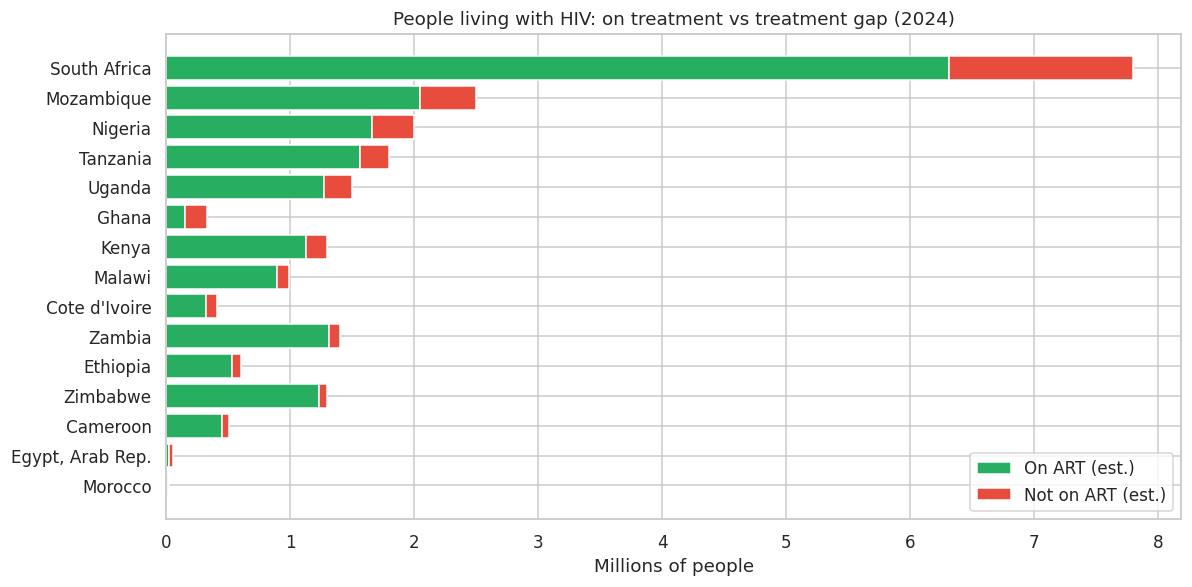

Total untreated across 15 countries: 3,582,860


In [14]:
gap = plhiv_latest.sort_values("treatment_gap", ascending=False)
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.barh(gap.country_name, gap.plhiv_on_art / 1e6, color="#27ae60", label="On ART (est.)")
ax.barh(gap.country_name, gap.treatment_gap / 1e6, left=gap.plhiv_on_art / 1e6,
        color="#e74c3c", label="Not on ART (est.)")
ax.invert_yaxis()
ax.set(title=f"People living with HIV: on treatment vs treatment gap ({LATEST})",
       xlabel="Millions of people", ylabel="")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()
print(f"Total untreated across 15 countries: {gap.treatment_gap.sum():,.0f}")

## 8. 90-90-90 progress

In [15]:
targets = (df[df.art_coverage_pct.notna()]
           .groupby("country_name")
           .agg(art_latest=("art_coverage_pct", "last"),
                first_year_81=("year", lambda y: y[df.loc[y.index, "meets_90_90_90_art"] == 1]
                               .min()))
           .sort_values("art_latest", ascending=False))
targets["status"] = np.select(
    [targets.art_latest >= 90.25, targets.art_latest >= 81],
    ["95-95-95 treatment level", "90-90-90 treatment level"], "Below target")
print(targets.status.value_counts().to_string())
targets

status
90-90-90 treatment level    9
Below target                4
95-95-95 treatment level    2


,art_latest,first_year_81,status
country_name,,,
Zimbabwe,95.0,2019.0,95-95-95 treatment level
Zambia,94.0,2020.0,95-95-95 treatment level
Malawi,90.0,2019.0,90-90-90 treatment level
Ethiopia,88.0,2022.0,90-90-90 treatment level
Cameroon,88.0,2023.0,90-90-90 treatment level
Kenya,87.0,2017.0,90-90-90 treatment level
Tanzania,87.0,2024.0,90-90-90 treatment level
Uganda,85.0,2023.0,90-90-90 treatment level
Nigeria,83.0,2024.0,90-90-90 treatment level


## 9. Key findings

1. **Southern Africa is the epicentre.** South Africa (17.2%), Mozambique (11.5%),
   Zimbabwe (9.8%) and Zambia (9.4%) have the highest adult prevalence in 2024;
   Egypt and Morocco are at 0.1%.
2. **Burden is concentrated.** South Africa alone has 7.8 million PLHIV — about 35%
   of the 22.5 million across the 15 countries; the top five countries hold ~69%.
3. **Treatment scale-up is a success story.** Average ART coverage rose from ~45%
   (2015) to ~80% (2024). 11 of 15 countries now reach the 81% "90-90-90" treatment
   level, and Zimbabwe (95%) and Zambia (94%) exceed the 95-95-95 equivalent.
4. **New infections are falling fast.** Average incidence dropped from 3.5 to
   1.4 per 1,000 uninfected adults; Mozambique and South Africa halved incidence
   but still exceed 4.9 per 1,000.
5. **The treatment gap is still ~3.6 million people**, about 41% of them in
   South Africa. Ghana (47%) and Egypt (45%) have the lowest ART coverage.
6. **Africa vs USA:** the US spends ~16.7% of GDP on health vs ~4.9% on average
   in these African countries. The World Bank reports no US HIV estimates, so
   US HIV outcome comparisons require CDC surveillance data.
7. **Spending follows the epidemic:** health expenditure correlates positively
   with HIV prevalence across African country-years (r ≈ 0.7), reflecting
   HIV-driven (often donor-funded) spending rather than spending causing HIV.

In [16]:
conn.close()